In [9]:
from langchain.chat_models import init_chat_model
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode,tools_condition

In [10]:
from dotenv import load_dotenv
load_dotenv()

True

In [11]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

In [14]:
@tool
def get_stock_price(symbol: str) -> float:
    '''Return the current price of a stock given the stock symbol
    :param symbol: stock symbol
    :return: current price of the stock
    '''
    return{
        "MSFT": 200.3,
        "AAPL": 100.4,
        "GOOGL": 250.0,
    }.get(symbol,0.0)

tools = [get_stock_price]
llm = init_chat_model("google_genai:gemini-3.5-flash")
llm_with_tools = llm.bind_tools(tools)

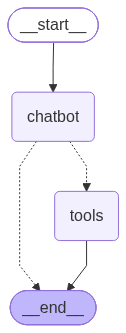

In [15]:
def chatbot(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node(chatbot)
builder.add_node("tools",ToolNode(tools))
builder.add_edge(START,"chatbot")
builder.add_conditional_edges("chatbot",tools_condition)
graph = builder.compile()
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
state = graph.invoke({"messages": [{"role": "user", "content": "What is the price of AAPL stock right now?"}]})
print(state["messages"][-1].content)

100.4


In [18]:
state = graph.invoke({"messages": [{"role": "user", "content": "Who invented theory of relativity? print person name only"}]})
print(state["messages"][-1].text)

Albert Einstein


In [19]:
msg = "I want to buy 20 AMZN stocks using current price. Then 15 MSFT. What will be the total cost?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]})
print(state["messages"][-1].content)

200.3
